In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [36]:
data = {
 "Study_Hours": [2, 3, 5, 1, 6, 4, 2, 7, 3, 8, 5, 1],

"Attendance": [60, 65, 75, 40, 85, 70,
               50, 90, 55, 95, 80, 35],

 "Previous_Marks": [45, 50, 60, 30, 70, 55,
                       35, 80, 40, 85, 65, 25],

 "Final_Marks": [48, 52, 65, 35, 78, 60,
                    40, 88, 45, 92, 72, 30],

 "Result": ["Fail", "Pass", "Pass", "Fail",
               "Pass", "Pass", "Fail", "Pass",
               "Fail", "Pass", "Pass", "Fail"]
}
df = pd.DataFrame(data)
df

,Study_Hours,Attendance,Previous_Marks,Final_Marks,Result
0,2,60,45,48,Fail
1,3,65,50,52,Pass
2,5,75,60,65,Pass
3,1,40,30,35,Fail
4,6,85,70,78,Pass
5,4,70,55,60,Pass
6,2,50,35,40,Fail
7,7,90,80,88,Pass
8,3,55,40,45,Fail
9,8,95,85,92,Pass


In [15]:
df.head()
df.tail()

,Study_Hours,Attendance,Previous_Marks,Final_Marks,Result
7,7,90,80,88,Pass
8,3,55,40,45,Fail
9,8,95,85,92,Pass
10,5,80,65,72,Pass
11,1,35,25,30,Fail


In [25]:
df.shape
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Study_Hours     12 non-null     int64 
 1   Attendance      12 non-null     int64 
 2   Previous_Marks  12 non-null     int64 
 3   Final_Marks     12 non-null     int64 
 4   Result          12 non-null     object
dtypes: int64(4), object(1)
memory usage: 612.0+ bytes


Study_Hours       0
Attendance        0
Previous_Marks    0
Final_Marks       0
Result            0
dtype: int64

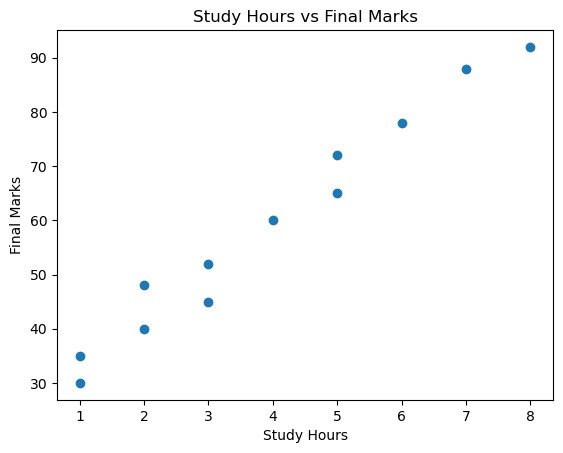

In [24]:
plt.scatter(df["Study_Hours"], df["Final_Marks"])
plt.xlabel("Study Hours")
plt.ylabel("Final Marks")
plt.title("Study Hours vs Final Marks")
plt.show()

In [23]:
X = df[["Study_Hours", "Attendance", "Previous_Marks"]]
y = df["Final_Marks"]
print("Input features:")
display(X.head())
print("Target variable:")
display(y.head())

Input features:


,Study_Hours,Attendance,Previous_Marks
0,2,60,45
1,3,65,50
2,5,75,60
3,1,40,30
4,6,85,70


Target variable:


0    48
1    52
2    65
3    35
4    78
Name: Final_Marks, dtype: int64

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y,
test_size=0.25,
random_state=42
)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (9, 3)
Testing data: (3, 3)


In [21]:
model = LinearRegression()
model.fit(X_train, y_train)
print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [20]:
y_pred = model.predict(X_test)

print("Actual Marks:", list(y_test))
print("Predicted Marks:", y_pred)

Actual Marks: [72, 92, 48]
Predicted Marks: [69.93412162 94.80067568 46.70101351]


In [26]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("R2 Score:", r2)

MAE: 2.055180180180185
MSE: 4.599667868882413
R2 Score: 0.9857839935371079


In [27]:
new_student = pd.DataFrame({
"Study_Hours": [6],
"Attendance": [85],
"Previous_Marks": [75]
})
predicted_marks = model.predict(new_student)
print("Predicted Final Marks:", predicted_marks[0])

Predicted Final Marks: 81.85135135135135


In [35]:
X = df[["Study_Hours", "Attendance", "Previous_Marks"]]
y = df["Result"]

In [38]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
test_size=0.25,
random_state=42,
stratify=y
)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (9, 3)
Testing data: (3, 3)


In [39]:
classifier = LogisticRegression()
classifier.fit(X_train, y_train)
print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [40]:
y_pred_class = classifier.predict(X_test)

print("Actual Results:", list(y_test))

print("Predicted Results:", list(y_pred_class))

Actual Results: ['Fail', 'Pass', 'Pass']
Predicted Results: ['Fail', 'Pass', 'Pass']


In [42]:
accuracy = accuracy_score(y_test, y_pred_class)
print("Model Accuracy:", accuracy)
print(classification_report(y_test, y_pred_class))

Model Accuracy: 1.0
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         1
        Pass       1.00      1.00      1.00         2

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3



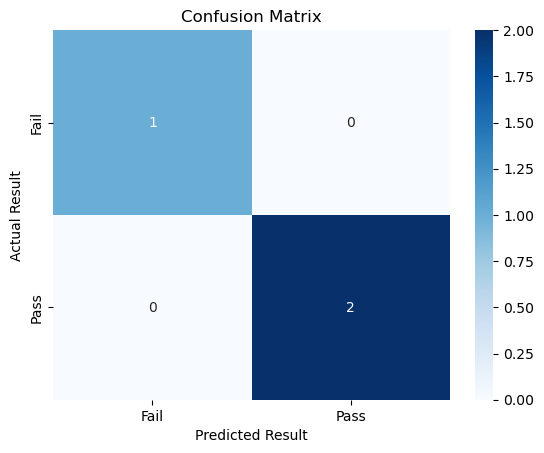

In [43]:
cm = confusion_matrix(
    y_test,
    y_pred_class,
    labels=["Fail", "Pass"]
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.title("Confusion Matrix")

plt.show()

In [44]:
new_student = pd.DataFrame({
    "Study_Hours": [6],
    "Attendance": [85],
    "Previous_Marks": [75]
})

prediction = classifier.predict(new_student)

print("Student Result:", prediction[0])

Student Result: Pass


In [11]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier

In [12]:
data = {
    "Study_Hours": [2, 3, 5, 1, 6, 4, 2, 7, 3, 8, 5, 1],
    "Attendance": [60, 65, 75, 40, 85, 70, 50, 90, 55, 95, 80, 35],
    "Previous_Marks": [45, 50, 60, 30, 75, 55, 40, 85, 48, 90, 70, 25],
    "Final_Marks": [40, 45, 65, 25, 80, 60, 35, 90, 42, 95, 75, 20],
    "Result": ["Fail", "Fail", "Pass", "Fail", "Pass", "Pass",
               "Fail", "Pass", "Fail", "Pass", "Pass", "Fail"]
}

df = pd.DataFrame(data)

print("OLD STUDENT DATA")
display(df)

OLD STUDENT DATA


,Study_Hours,Attendance,Previous_Marks,Final_Marks,Result
0,2,60,45,40,Fail
1,3,65,50,45,Fail
2,5,75,60,65,Pass
3,1,40,30,25,Fail
4,6,85,75,80,Pass
5,4,70,55,60,Pass
6,2,50,40,35,Fail
7,7,90,85,90,Pass
8,3,55,48,42,Fail
9,8,95,90,95,Pass


In [13]:
X = df[["Study_Hours", "Attendance", "Previous_Marks"]]

y_marks = df["Final_Marks"]
y_result = df["Result"]

model = LinearRegression()
classifier = DecisionTreeClassifier(random_state=42)

model.fit(X, y_marks)
classifier.fit(X, y_result)

print("Models trained successfully!")

Models trained successfully!


In [17]:
print("ENTER NEW STUDENT DETAILS")

name = input("Enter Student Name: ")
hours = float(input("Enter Study Hours: "))
attendance = float(input("Enter Attendance: "))
previous = float(input("Enter Previous Marks: "))

new_student = pd.DataFrame({
    "Study_Hours": [hours],
    "Attendance": [attendance],
    "Previous_Marks": [previous]
})

marks = model.predict(new_student)
result = classifier.predict(new_student)

print("\nNEW STUDENT PREDICTION")
print("Name:", name)
print("Study Hours:", hours)
print("Attendance:", attendance)
print("Previous Marks:", previous)
print("Predicted Final Marks:", round(marks[0], 2))
print("Predicted Result:", result[0])

ENTER NEW STUDENT DETAILS


Enter Student Name:  ds
Enter Study Hours:  34
Enter Attendance:  34
Enter Previous Marks:  34



NEW STUDENT PREDICTION
Name: ds
Study Hours: 34.0
Attendance: 34.0
Previous Marks: 34.0
Predicted Final Marks: 157.9
Predicted Result: Fail
